**My mission statement** "My mission is to build a software platform that enhances workforce development, 
empowers businesses, and creates job opportunities by improving education through 
connecting students and job seekers with real-world business challenges and 
internship experiences. This solution will transform business challenges into learning 
and employment opportunities for African youth."

## project use case
The aim of this project is to examine the relationship between educational attainment, technical and vocational education and training (TVET), and selected demography and employment data for the monthly cash earnings of employees in Rwanda. this regression model predicts expected monthly cash earnings (in RWF) using microdata from the National Institute of Statistics of Rwanda (NISR) Labour Force Surveys (2023–2024)

**Who uses the prediction:** Students, young job seekers, career advisors, workforce-development programme planners, employers and educational institutions.
**What they use it for:** They can use this prediction to compare fair entry-level compensation across Rwandan provinces and education levels, which will enable youth to make informed choices about their training and also help employers to set competitive, data-driven wages. 
this will enhance workforce development and bridge information gap where student will be able to prioritize skills that will lead them to stronger economic mobility.

## Dataset
**Source:** National Institute of Statistics of Rwanda (NISR), Rwanda Labour Force Survey 2024 and Rwanda Labour Force Survey 2023
**link** https://data.gov.rw/collections/47ba8734-adbf-4a38-9784-0b118eafe1e1

### 1. Importing libraries and load full dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import joblib

In [2]:
RANDOM_STATE = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

In [3]:
# locating data directory
WD = Path.cwd()
if (WD / "data").is_dir():
    DATA_DIR = WD / "data"
elif (WD.parent / "data").is_dir():
    DATA_DIR = WD.parent / "data"
else:
    DATA_DIR = WD / "data"
# combining all datasets
DATASETS = {
    2023: DATA_DIR / "labour_force_2023.csv",
    2024: DATA_DIR / "labour_force_2024.csv",
}
# loading data while cleaning the headers
def load_lfs_file(path: Path, year: int) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required {year} dataset: {path.resolve()}\n"
        )
    df = pd.read_csv(path, low_memory=False)
    df.columns = df.columns.astype(str).str.strip().str.lower()
    return df

In [4]:
# identifying column names from two dataset
df_2023 = load_lfs_file(DATASETS[2023], 2023)
df_2024 = load_lfs_file(DATASETS[2024], 2024)
print("== 2023 Columns ==")
print(", ".join(df_2023.columns))

print("\n== 2024 Columns ==")
print(", ".join(df_2024.columns))

== 2023 Columns ==
id, psu_no, qh_no, hhid, pid, province, code_ur, code_dis, lfs_year, weight2, a01, a02, a03m, a03y, a04, a05, a06, a07, a08, a09, a10, a11, a12, a13, a14a, a14b, a15, a16y, a17a, a17b, a18, a19, a20, a21, a22, a23, a24, b01, b02a, b02b, b03, b06, b07, b08, b09, b10, b13, b13a, b14, b18, b19, c01, c02, c03, c04, c05, c06, c07, c08, c09, c09a, c10, c11a, c11b, c12a, c12b, c13a, c13b, c14, c15, c16, c17, c18, c19, c20, c22, c23, c24, c25, c26, c21, c21_a, c21_b, c21_c, c21_d, c21_e, c21_f, c21_g, c21_h, c21_l, d03a, d04, d05, d06, d07, d08, d09a, d09b, d10a, d10b, d10c, d10d, d11, d12, d12a, d13, d14, d15, d15a, d16, d17, d20, d21, d23, d27, d24a, e11, e12, e12b, e13, f01, f02, f05, g01, g02, g03, g04, g05, g06, g07, g01a, g02a, g03a, g04a, g05a, g06a, g07a, h01, h02, h03, h05, h06, h09, h00, h04, h10, i01_a, i01_b, i01_c, i02, i03, i04, i05, i06a, i06b, i07a, i07b, i07c, i07d, i07e, i07f, i07g, i07h, i07i, i07j, i07k, i07l, i07m, i07n, i07o, i07p, i07q, status1, wap16,

In [5]:
# Loading all datasets and checking for missing ones
loaded_dfs = []
for year, file_path in DATASETS.items():
    print(f"Loading {year} data from: {file_path.resolve()} ...")
    df_year = load_lfs_file(file_path, year)
    # renaming d24a column in 2023 to match d24 in 2024 data
    df_year = df_year.rename(columns={"d24a": "d24"})
    loaded_dfs.append(df_year)

combined_df = pd.concat(loaded_dfs, ignore_index=True, join="inner")
print(f"\nSuccessfully merged {len(loaded_dfs)} datasets!")
print(f"Combined Dataset shape: {combined_df.shape[0]:,} rows x {combined_df.shape[1]:,} columns")
print("\nRecords per year:")
print(combined_df["lfs_year"].value_counts().sort_index())
display(combined_df.head())

Loading 2023 data from: /home/kevin/repos/linear_regression_model/summative/data/labour_force_2023.csv ...
Loading 2024 data from: /home/kevin/repos/linear_regression_model/summative/data/labour_force_2024.csv ...

Successfully merged 2 datasets!
Combined Dataset shape: 174,411 rows x 172 columns

Records per year:
lfs_year
2023     71849
2024    102562
Name: count, dtype: int64


,id,psu_no,qh_no,hhid,pid,province,code_ur,code_dis,lfs_year,weight2,a01,a02,a03m,a03y,a04,a05,a06,a07,a08,a09,a10,a11,a12,a13,a14a,a14b,a15,a16y,a17a,a17b,...,ya,hr_own,subhrs,hr_cshmain,hr_cash,tvt2,prod_unit,ud,iev2,head,dg01,dg02,dg03,dg04,dg05,dg06,dg07,age3,tvt,lu2,lu3,lu4,trur,indb05,isco2digit,isic2digitdigit,indd01,indd03,age3_16_30,yur1
0,1,5802,1,580201,58020101,1,2,11,2023,26.24,1,1,1,1991,32,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1,1,1,26.00,1,3.00,1.00,28.00,...,2.00,NaN,NaN,NaN,NaN,2.00,1.00,NaN,2.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,0.00,0.00,0.00,0.00,0.00,0.00,52.00,47.00,5.00,7.00,NaN,NaN
1,2,5802,1,580201,58020102,1,2,11,2023,26.24,2,2,1,1995,28,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1,1,1,28.00,1,2.00,1.00,28.00,...,1.00,14.00,NaN,NaN,NaN,3.00,1.00,NaN,2.00,NaN,NaN,NaN,NaN,NaN,NaN,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,52.00,47.00,5.00,7.00,3.00,0.00
2,3,5802,1,580201,58020103,1,2,11,2023,26.24,2,3,4,2022,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,11.00,2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,5802,2,580202,58020201,1,2,11,2023,26.24,1,1,1,1990,33,3.00,1.00,1.00,2.00,1.00,1.00,1.00,1,1,1,35.00,1,1.00,1.00,12.00,...,2.00,NaN,NaN,NaN,NaN,2.00,1.00,NaN,2.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.00,1.00,100.00,0.00,100.00,100.00,7.00,75.00,16.00,7.00,3.00,NaN,NaN
4,5,5802,2,580202,58020202,1,2,11,2023,26.24,2,2,1,1998,25,3.00,1.00,1.00,1.00,1.00,1.00,1.00,1,1,1,35.00,1,1.00,1.00,35.00,...,1.00,14.00,NaN,NaN,NaN,3.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,NaN,1.00,1.00,NaN,100.00,100.00,NaN,0.00,NaN,NaN,NaN,NaN,3.00,NaN


### 2. Selecting target and variables and cleaning them
According to NSIR documentation, the variable cash holds monthly income for employees, so I selected it as the target. variable choosen and their meaning:

**Numeric inputs**: A04 (age), B02B (years completed at the reported education level), D24 (total work experience).
**Categorical inputs**: A01 (sex), Code_UR (urban/rural), province, A05 (marital status), B02A (highest education level attended), B07 (currently attending trade/technical skills school), B08 (learned a TVET course), main_sect (economic sector).

In [7]:
TARGET = "cash"
NUMERIC_FEATURES = ["a04", "b02b", "d24"]
CATEGORICAL_FEATURES = ["a01", "code_ur", "province", "a05", "b02a", "b07", "b08", "main_sect"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
REQUIRED_COLUMNS = FEATURES + [TARGET]

missing_columns = [column for column in REQUIRED_COLUMNS if column not in combined_df.columns]
if missing_columns:
    raise KeyError(
        "These required columns are missing from the file: " + ", ".join(missing_columns)
    )
# cleaning numeric features and ensuring target has valid positive monthly income 
for column in [TARGET] + NUMERIC_FEATURES:
    combined_df[column] = pd.to_numeric(combined_df[column], errors="coerce")

model_df = combined_df[REQUIRED_COLUMNS].copy()
model_df = model_df.replace([np.inf, -np.inf], np.nan)
model_df = model_df.loc[model_df[TARGET].notna() & (model_df[TARGET] > 0)].copy()
X = model_df[FEATURES].copy()
y = model_df[TARGET].astype(float).copy()

print(f"Rows in combined file: {len(combined_df):,}")
print(f"Rows with a valid positive {TARGET} target: {len(model_df):,}")
print(f"Number of input features: {len(FEATURES)}")

Rows in combined file: 174,411
Rows with a valid positive cash target: 36,645
Number of input features: 11


### 3. checking for missing values to know which feature needs imputation

In [8]:
missing_summary = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_percent": (X.isna().mean() * 100).round(2),
    "data_type": X.dtypes.astype(str),
}).sort_values("missing_percent", ascending=False)
display(missing_summary)

print("Exact duplicate rows:", combined_df.duplicated().sum())
print("Target skewness:", round(float(y.skew()), 3))
print("Target minimum:", f"RWF {y.min():,.0f}")
print("Target median:", f"RWF {y.median():,.0f}")
print("Target mean:", f"RWF {y.mean():,.0f}")
print("Target maximum:", f"RWF {y.max():,.0f}")

,missing_count,missing_percent,data_type
b08,565,1.54,float64
b02b,0,0.00,float64
a04,0,0.00,int64
d24,0,0.00,float64
a01,0,0.00,int64
province,0,0.00,int64
code_ur,0,0.00,int64
a05,0,0.00,float64
b02a,0,0.00,float64
b07,0,0.00,float64


Exact duplicate rows: 0
Target skewness: 26.843
Target minimum: RWF 700
Target median: RWF 35,000
Target mean: RWF 77,405
Target maximum: RWF 15,000,000


### 4. Exploratory data analysis
Visualization1: correlation heatmap

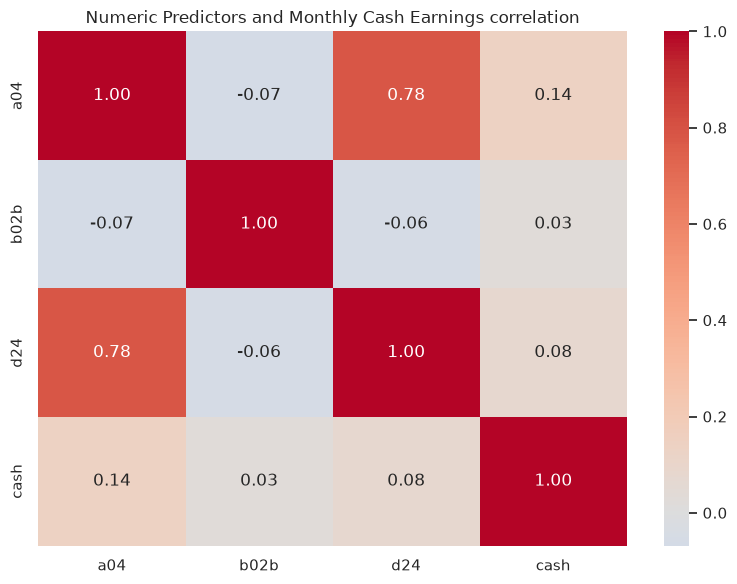

,spearman correlation ascending order
a04,0.14
d24,0.08
b02b,0.03


In [9]:
numeric_for_corr = NUMERIC_FEATURES + [TARGET]
correlation_matrix = model_df[numeric_for_corr].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Numeric Predictors and Monthly Cash Earnings correlation")
plt.tight_layout()
plt.show()

target_correlations = correlation_matrix[TARGET].drop(
    TARGET).sort_values(key=lambda values: values.abs(), ascending=False)
display(target_correlations.to_frame("spearman correlation ascending order"))

#### Interpretation of Visualization 1
The Spearman correlation heatmap shows the relationships between the numerical features and monthly cash earnings (cash). Age (A04) has the strongest positive correlation with earnings (0.14), followed by work experience (D24, 0.08) and completed years of education (B02B, 0.03); it also shows that none of these numeric features have a strong relationship with earnings, so this is the reason I decided to keep key categorical predictors like education level, sector, province, and urban/rural status, and will normalise all features before modeling. 

### visualization 2: distribution of monthly cash earning

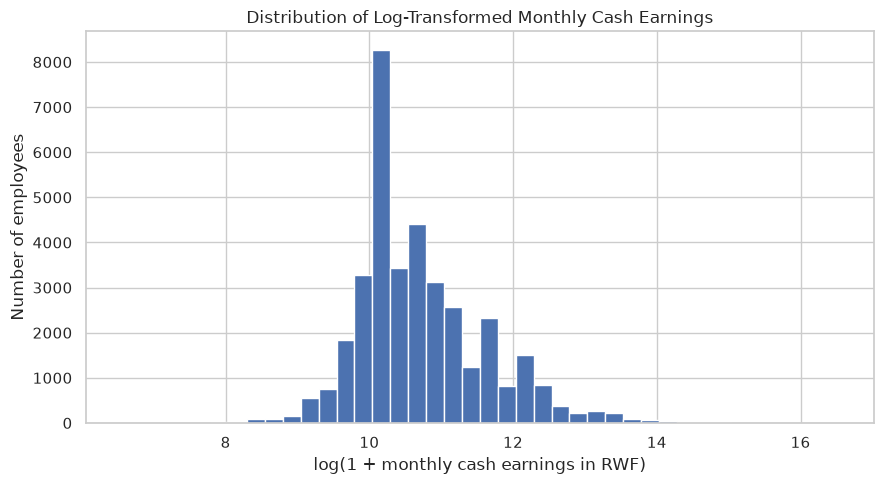

Skewness of raw earnings: 26.843
Skewness after log1p: 0.934


In [10]:
plt.figure(figsize=(9, 5))
plt.hist(np.log1p(y), bins=40)
plt.title("Distribution of Log-Transformed Monthly Cash Earnings")
plt.xlabel("log(1 + monthly cash earnings in RWF)")
plt.ylabel("Number of employees")
plt.tight_layout()
plt.show()

print("Skewness of raw earnings:", round(float(y.skew()), 3))
print("Skewness after log1p:", round(float(np.log1p(y).skew()), 3))

#### Interpretation of Visualization 2
The monthly cash earnings distribution is very highly skewed(26.843) because of extreme outliers reaching up to RWF 15,000,000, while np.log1p has brought the distribution to an almost symmetric curve(0.934). I found that the extreme outliers strongly influenced Mean Squared Error (MSE) and the gradient descent for raw RWF, so I chose to train all models on the log-transformed earnings (np.log1p(cash)) and convert back to raw RWF during evaluation using np.expm1.

### 5. Feature engineering and scatter plot

#### scatter plot before fitting

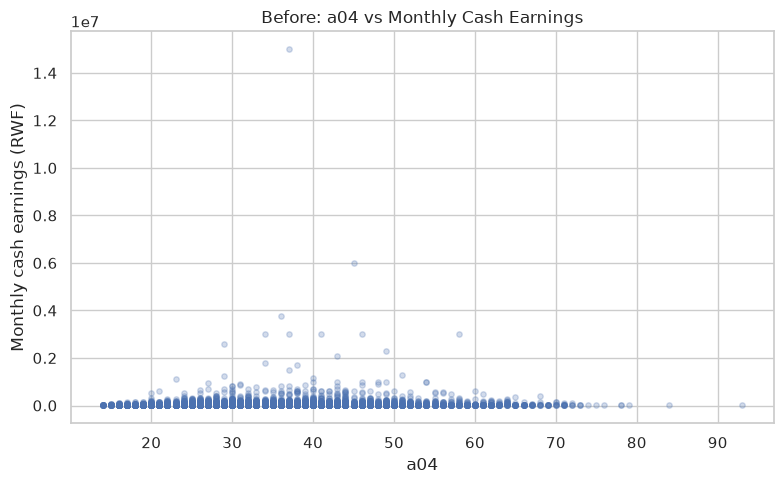

Feature selected for the required one-feature scatter plots: a04


In [11]:
best_numeric_feature = target_correlations.abs().idxmax()
scatter_df = model_df[[best_numeric_feature, TARGET]].dropna().copy()
# Limit displayed points for readability
plot_points = scatter_df.sample(n=min(5000, len(scatter_df)), random_state=RANDOM_STATE)
plt.figure(figsize=(8, 5))
plt.scatter(plot_points[best_numeric_feature], plot_points[TARGET], alpha=0.25, s=15)
plt.title(f"Before: {best_numeric_feature} vs Monthly Cash Earnings")
plt.xlabel(best_numeric_feature)
plt.ylabel("Monthly cash earnings (RWF)")
plt.tight_layout()
plt.show()

print("Feature selected for the required one-feature scatter plots:", best_numeric_feature)

#### Interpretation of scatter plot before fitting
This scatter plot display the relationship between age(a04) and monthly earnings, on the graph we can see that there are few outliers which suggest a lot of variation in earnings.This indicates weak association of age with monthly earnings; however it is useful as one of the input features in the multivariate regression models.

#### scatter plot after fitting

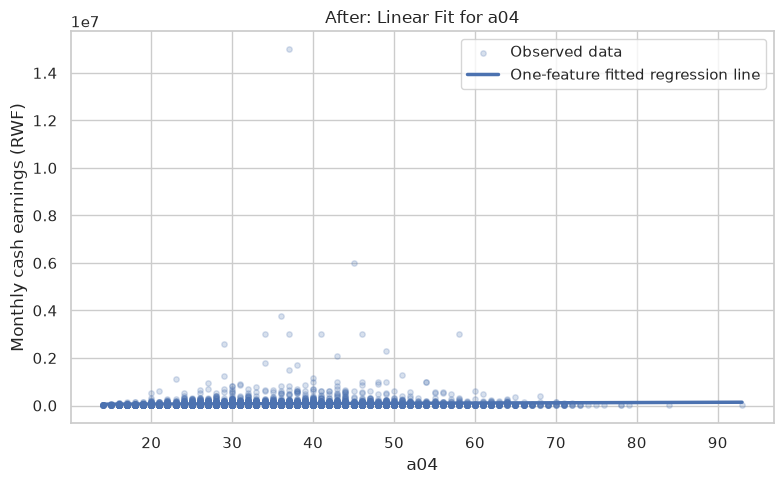

One-feature slope: 1044.2636751860662
One-feature intercept: 41105.95307473666


In [12]:
one_feature_model = LinearRegression()
one_feature_model.fit(scatter_df[[best_numeric_feature]], scatter_df[TARGET])

x_line = np.linspace(
    scatter_df[best_numeric_feature].min(),
    scatter_df[best_numeric_feature].max(),
    200,
).reshape(-1, 1)
x_line_df = pd.DataFrame(x_line, columns=[best_numeric_feature])
y_line = one_feature_model.predict(x_line_df)

plt.figure(figsize=(8, 5))
plt.scatter(plot_points[best_numeric_feature], plot_points[TARGET], alpha=0.22, s=15, label="Observed data")
plt.plot(x_line.ravel(), y_line, linewidth=2.5, label="One-feature fitted regression line")
plt.title(f"After: Linear Fit for {best_numeric_feature}")
plt.xlabel(best_numeric_feature)
plt.ylabel("Monthly cash earnings (RWF)")
plt.legend()
plt.tight_layout()
plt.show()

print("One-feature slope:", float(one_feature_model.coef_[0]))
print("One-feature intercept:", float(one_feature_model.intercept_))

#### Interpretation of scatter plot after fitting
There is a small positive relationship between age and monthly cash earnings as can be seen from the fitted regression line which shows that with an increase of age, the earnings can be predicted to increase slightly. The line does not capture the wide range of earnings that are seen on the scatter graph. This validates the need for having multiple features to account for earnings differences, as age alone is not enough.

### 6. Splitting data

In [13]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE)

print(f"Training data for final model: {len(X_train_full):,}")
print(f"Validation data for SGD tuning: {len(X_validation):,}")
print(f"Final test data: {len(X_test):,}")

Training data for final model: 29,316
Validation data for SGD tuning: 5,864
Final test data: 7,329


### 7. Building preprocessing

In [14]:
def make_preprocessor():
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),])
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),])

### 8. Tuning SGDRegressor using partial_fit

In [15]:
tuning_preprocessor = make_preprocessor()
X_train_processed = tuning_preprocessor.fit_transform(X_train)
X_validation_processed = tuning_preprocessor.transform(X_validation)
y_train_log = np.log1p(y_train.to_numpy(dtype=float))
tuning_rows = []
best_sgd_settings = None
best_validation_mse = np.inf
MAX_TUNING_EPOCHS = 80

for eta0 in [0.0005, 0.001, 0.005]:
    for alpha in [0.0001, 0.001]:
        candidate = SGDRegressor(
            loss="squared_error",
            penalty="l2",
            alpha=alpha,
            learning_rate="constant",
            eta0=eta0,
            random_state=RANDOM_STATE,)
        candidate_best_mse = np.inf
        candidate_best_epoch = None
        rng = np.random.default_rng(RANDOM_STATE)

        for epoch in range(1, MAX_TUNING_EPOCHS + 1):
            order = rng.permutation(X_train_processed.shape[0])
            candidate.partial_fit(
                X_train_processed[order],
                y_train_log[order],
            )
            validation_log_prediction = candidate.predict(X_validation_processed)
            validation_prediction = np.maximum(0, np.expm1(validation_log_prediction))
            validation_mse = mean_squared_error(y_validation, validation_prediction)

            if np.isfinite(validation_mse) and validation_mse < candidate_best_mse:
                candidate_best_mse = validation_mse
                candidate_best_epoch = epoch

        tuning_rows.append({
            "eta0": eta0,
            "alpha": alpha,
            "best_epoch": candidate_best_epoch,
            "best_validation_mse": candidate_best_mse,})
        if candidate_best_mse < best_validation_mse:
            best_validation_mse = candidate_best_mse
            best_sgd_settings = {
                "eta0": eta0,
                "alpha": alpha,
                "epochs": candidate_best_epoch,}

sgd_tuning_results = pd.DataFrame(tuning_rows).sort_values("best_validation_mse")
display(sgd_tuning_results)
print("Selected SGD settings:", best_sgd_settings)
print("Best validation MSE (RWF^2):", f"{best_validation_mse:,.2f}")
if best_sgd_settings is None or best_sgd_settings["epochs"] is None:
    raise RuntimeError("SGD tuning did not produce a finite validation result. Try a smaller eta0.")

,eta0,alpha,best_epoch,best_validation_mse
4,0.01,0.00,53,"19,563,474,210.26"
5,0.01,0.00,11,"19,570,640,554.80"
2,0.00,0.00,11,"19,959,813,850.96"
3,0.00,0.00,11,"20,002,164,814.64"
0,0.00,0.00,48,"20,132,669,325.36"
1,0.00,0.00,48,"20,180,441,508.01"


Selected SGD settings: {'eta0': 0.005, 'alpha': 0.0001, 'epochs': 53}
Best validation MSE (RWF^2): 19,563,474,210.26


### 9. Training all four models

In [16]:
# Fitting preprocessing on the full 80% training split only.
final_preprocessor = make_preprocessor()
X_train_processed = final_preprocessor.fit_transform(X_train_full)
X_test_processed = final_preprocessor.transform(X_test)
y_train_log = np.log1p(y_train_full.to_numpy(dtype=float))
y_test_array = y_test.to_numpy(dtype=float)

# Training the selected SGDRegressor with partial_fit and record loss after each epoch.
sgd_final = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=best_sgd_settings["alpha"],
    learning_rate="constant",
    eta0=best_sgd_settings["eta0"],
    random_state=RANDOM_STATE,
)

sgd_train_mse_curve = []
sgd_test_mse_curve = []
rng = np.random.default_rng(RANDOM_STATE)

for epoch in range(1, best_sgd_settings["epochs"] + 1):
    order = rng.permutation(X_train_processed.shape[0])
    sgd_final.partial_fit(X_train_processed[order], y_train_log[order])

    train_prediction = np.maximum(0, np.expm1(sgd_final.predict(X_train_processed)))
    test_prediction = np.maximum(0, np.expm1(sgd_final.predict(X_test_processed)))
    sgd_train_mse_curve.append(mean_squared_error(y_train_full, train_prediction))
    sgd_test_mse_curve.append(mean_squared_error(y_test_array, test_prediction))

sgd_pipeline = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    ("regressor", sgd_final),
])



### 10. comparing all four models

In [17]:
# Fitting the other models on the same training rows and the same log-transformed target.
other_estimators = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "RandomForestRegressor": RandomForestRegressor(
        n_estimators=120, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

model_pipelines = {"SGDRegressor": sgd_pipeline}
for model_name, estimator in other_estimators.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("regressor", estimator),
    ])
    pipeline.fit(X_train_full, y_train_log)
    model_pipelines[model_name] = pipeline


def predict_cash(pipeline, features_frame):
    # Convert predictions from log earnings back to RWF.
    predicted_log = pipeline.predict(features_frame)
    return np.maximum(0, np.expm1(predicted_log))

results = []
for model_name, pipeline in model_pipelines.items():
    train_prediction = predict_cash(pipeline, X_train_full)
    test_prediction = predict_cash(pipeline, X_test)
    results.append({
        "Model": model_name,
        "Train MSE (RWF^2)": mean_squared_error(y_train_full, train_prediction),
        "Test MSE (RWF^2)": mean_squared_error(y_test, test_prediction),
        "Test RMSE (RWF)": mean_squared_error(y_test, test_prediction) ** 0.5,
        "Test MAE (RWF)": mean_absolute_error(y_test, test_prediction),
        "Test R2": r2_score(y_test, test_prediction),
    })

results_df = pd.DataFrame(results).sort_values("Test MSE (RWF^2)").reset_index(drop=True)
display(results_df)

best_model_name = results_df.loc[0, "Model"]
best_pipeline = model_pipelines[best_model_name]
print(f"Best model by lowest test MSE: {best_model_name}")
print(f"Lowest test MSE: {results_df.loc[0, 'Test MSE (RWF^2)']:,.2f} RWF^2")

,Model,Train MSE (RWF^2),Test MSE (RWF^2),Test RMSE (RWF),Test MAE (RWF),Test R2
0,RandomForestRegressor,"17,510,464,513.62","47,362,130,610.50","217,628.42","37,209.79",0.23
1,DecisionTreeRegressor,"18,604,815,194.52","47,378,342,805.50","217,665.67","38,808.16",0.23
2,SGDRegressor,"22,335,151,672.92","52,701,275,625.74","229,567.58","40,915.99",0.15
3,LinearRegression,"22,325,197,584.85","52,764,426,724.19","229,705.09","40,794.04",0.15


Best model by lowest test MSE: RandomForestRegressor
Lowest test MSE: 47,362,130,610.50 RWF^2


### 11. Knowing which feature matters most to the target

,feature,importance_mean,importance_std
7,b02a,"39,534,182,028.74","1,265,098,832.67"
1,b02b,"28,366,700,738.25","327,274,913.60"
5,province,"26,409,072,894.77","321,038,051.64"
3,a01,"24,071,963,029.77","72,439,137.03"
6,a05,"23,820,233,286.44","439,928,449.43"
10,main_sect,"23,656,678,477.30","82,796,472.70"
4,code_ur,"23,560,350,899.48","164,565,370.42"
2,d24,"23,334,409,501.63","1,362,711,186.12"
9,b08,"23,231,701,557.32","138,582,930.61"
8,b07,"22,936,592,804.22","1,290,565.21"


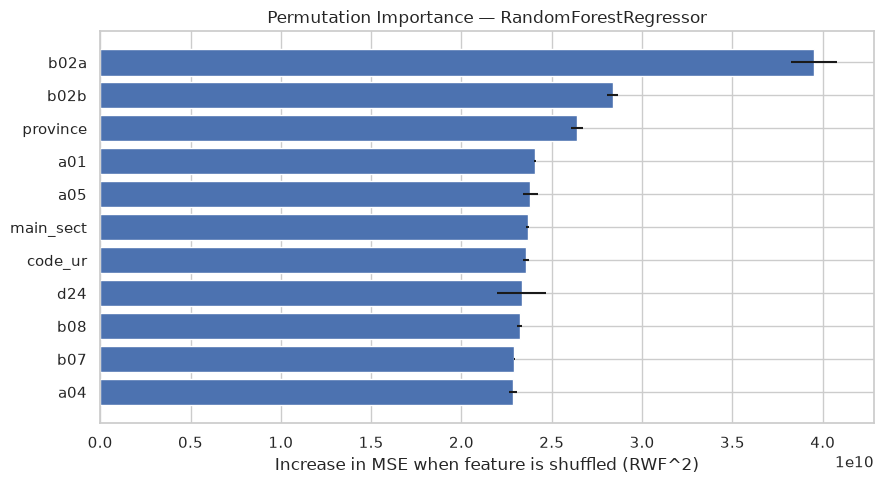

In [18]:
def negative_mse_in_rwf(estimator, features_frame, actual_cash):
    predicted_cash = np.maximum(0, np.expm1(estimator.predict(features_frame)))
    return -mean_squared_error(actual_cash, predicted_cash)

importance_result = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring=negative_mse_in_rwf,
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_samples=0.5,)

importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance_df)
plt.figure(figsize=(9, 5))
plot_importance = importance_df.sort_values("importance_mean", ascending=True)
plt.barh(plot_importance["feature"], plot_importance["importance_mean"], xerr=plot_importance["importance_std"])
plt.xlabel("Increase in MSE when feature is shuffled (RWF^2)")
plt.title(f"Permutation Importance — {best_model_name}")
plt.tight_layout()
plt.show()

#### Interpretation of this visualization
The permutation importance chart for RandomForestRegressor shows that education level (b02a) is the strongest predictor of monthly cash earnings. Because all 11 features show substantial positive importance, I decided to retain all 11 predictors in the final saved pipeline (best_model.pkl) rather than dropping any variables.

### 12. Required SGDRegressor loss curve

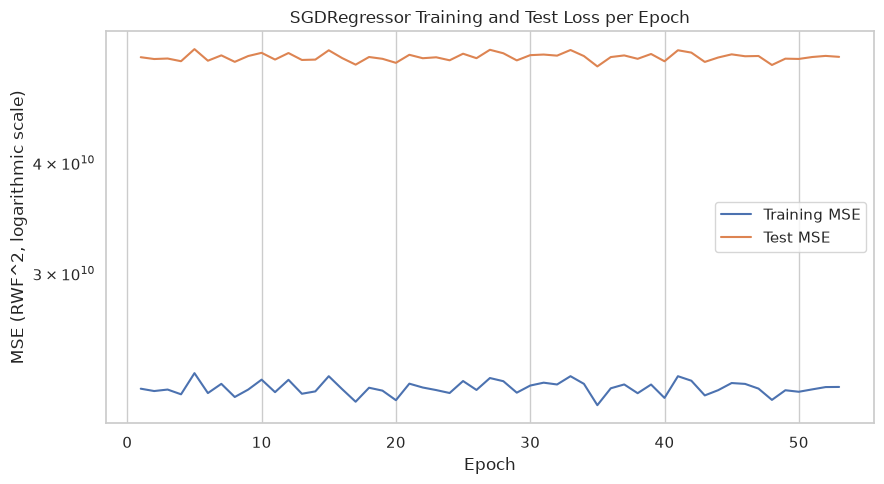

SGD hyperparameters: {'eta0': 0.005, 'alpha': 0.0001, 'epochs': 53}


In [19]:
epochs = np.arange(1, len(sgd_train_mse_curve) + 1)
plt.figure(figsize=(9, 5))
plt.plot(epochs, sgd_train_mse_curve, label="Training MSE")
plt.plot(epochs, sgd_test_mse_curve, label="Test MSE")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (RWF^2, logarithmic scale)")
plt.title("SGDRegressor Training and Test Loss per Epoch")
plt.legend()
plt.tight_layout()
plt.show()
print("SGD hyperparameters:", best_sgd_settings)

### 13. Saving best model and pre processing

In [20]:
# Support both common working directories.
if (WD / "API").is_dir():
    API_DIR = WD / "API"
elif (WD.parent / "API").is_dir():
    API_DIR = WD.parent / "API"
else:
    API_DIR = WD / "API"
MODEL_PATH = API_DIR / "best_model.pkl"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "pipeline": best_pipeline,
    "target_transform": "log1p",
    "feature_columns": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "target_column": TARGET,
    "target_unit": "RWF per month",
    "best_model_name": best_model_name,
    "sgd_settings": best_sgd_settings,
    "training_X": X_train_full.copy(),
    "training_y": y_train_full.copy(),
}

joblib.dump(model_artifact, MODEL_PATH)
results_df.to_csv("model_comparison.csv", index=False)
print("Saved model artifact to:", MODEL_PATH.resolve())
print("Saved comparison table to:", Path("model_comparison.csv").resolve())

Saved model artifact to: /home/kevin/repos/linear_regression_model/summative/API/best_model.pkl
Saved comparison table to: /home/kevin/repos/linear_regression_model/summative/linear_regression/model_comparison.csv


### 14. Load one saved model to predict one test observation

In [21]:
def predict_single_row(input_row: pd.DataFrame | dict, model_path: Path = MODEL_PATH) -> float:
    artifact = joblib.load(model_path)
    pipeline = artifact["pipeline"]
    feature_cols = artifact["feature_columns"]
    if isinstance(input_row, dict):
        row_df = pd.DataFrame([input_row])[feature_cols]
    else:
        row_df = input_row[feature_cols].copy()
    return float(np.maximum(0, np.expm1(pipeline.predict(row_df)[0])))

one_test_row = X_test.iloc[[0]].copy()
actual_cash = float(y_test.iloc[0])
predicted_cash = predicted_cash = predict_single_row(one_test_row)

print("Actual monthly cash earnings:", f"RWF {actual_cash:,.0f}")
print("Predicted monthly cash earnings:", f"RWF {predicted_cash:,.0f}")
print("Absolute prediction error:", f"RWF {abs(actual_cash - predicted_cash):,.0f}")
display(one_test_row)

Actual monthly cash earnings: RWF 65,000
Predicted monthly cash earnings: RWF 47,138
Absolute prediction error: RWF 17,862


,a04,b02b,d24,a01,code_ur,province,a05,b02a,b07,b08,main_sect
141515,38,3.00,20.00,1,2,5,3.00,3.00,2.00,2.00,2.00
